# OPE-7: Non-Linear Filtering for Image Noise Removal

**Aim:** Identify visible noise in the supplied images, apply non-linear filters, compare filter sizes/types, study edge/detail preservation, and record failure cases.

This notebook:
- Reads the four images in grayscale.
- Applies median filters (3×3, 5×5, 7×7), alpha-trimmed mean, bilateral, and rank filters (minimum/maximum).
- Displays comparisons and saves report-ready screenshots.
- Computes an edge-strength indicator for comparison.
- Creates a summary table and saves results.


## 1. Import libraries and set image paths



In [ ]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import os
from pathlib import Path

image_paths = [
    r"D:\MARWADI\YEAR3\SEM5\DSIP\OPE\OPE5\Screenshot 2026-11-07 225455.png",
    r"D:\MARWADI\YEAR3\SEM5\DSIP\OPE\OPE5\Screenshot 2026-11-07 225504.png",
    r"D:\MARWADI\YEAR3\SEM5\DSIP\OPE\OPE5\Screenshot 2026-11-07 225513.png",
    r"D:\MARWADI\YEAR3\SEM5\DSIP\OPE\OPE5\Screenshot 2026-11-07 225526.png"
]

# All output images and screenshots will be saved here
output_dir = "OPE7_Results"
os.makedirs(output_dir, exist_ok=True)

print("Output folder:", os.path.abspath(output_dir))

Output folder: d:\MARWADI\YEAR3\SEM5\DSIP\OPE\OPE5\OPE7_Results


## 2. Load images in grayscale

The images are converted to grayscale because the experiment focuses on spatial noise removal. If an image cannot be read, check its path.

In [3]:
images = []

for i, path in enumerate(image_paths):
    img = cv2.imread(path, cv2.IMREAD_GRAYSCALE)

    if img is None:
        print("Could not read Image", i + 1, ":", path)
    else:
        images.append(img)
        print(
            "Image", i + 1,
            "| Shape:", img.shape,
            "| Minimum:", img.min(),
            "| Maximum:", img.max(),
            "| Mean:", round(img.mean(), 2),
            "| Standard deviation:", round(img.std(), 2)
        )

if len(images) == 0:
    raise ValueError("No images were loaded. Check the four image paths.")

Image 1 | Shape: (308, 277) | Minimum: 0 | Maximum: 255 | Mean: 162.09 | Standard deviation: 77.55
Image 2 | Shape: (312, 215) | Minimum: 0 | Maximum: 255 | Mean: 107.14 | Standard deviation: 73.23
Image 3 | Shape: (257, 502) | Minimum: 0 | Maximum: 255 | Mean: 107.06 | Standard deviation: 62.44
Image 4 | Shape: (247, 506) | Minimum: 0 | Maximum: 230 | Mean: 142.45 | Standard deviation: 38.86


## 3. Display original images

Inspect the images before filtering. Identify whether the visible disturbance looks like isolated black/white dots, granular noise, or repeated stripes/patterns.

**Initial visual classification (to be checked against the displayed images):**
- Images 3 and 4 appear to contain strong impulse-like noise.
- Images 1 and 2 show visible structured/periodic patterns as well as granular variations.
- Appearance alone does not prove the exact statistical noise model.

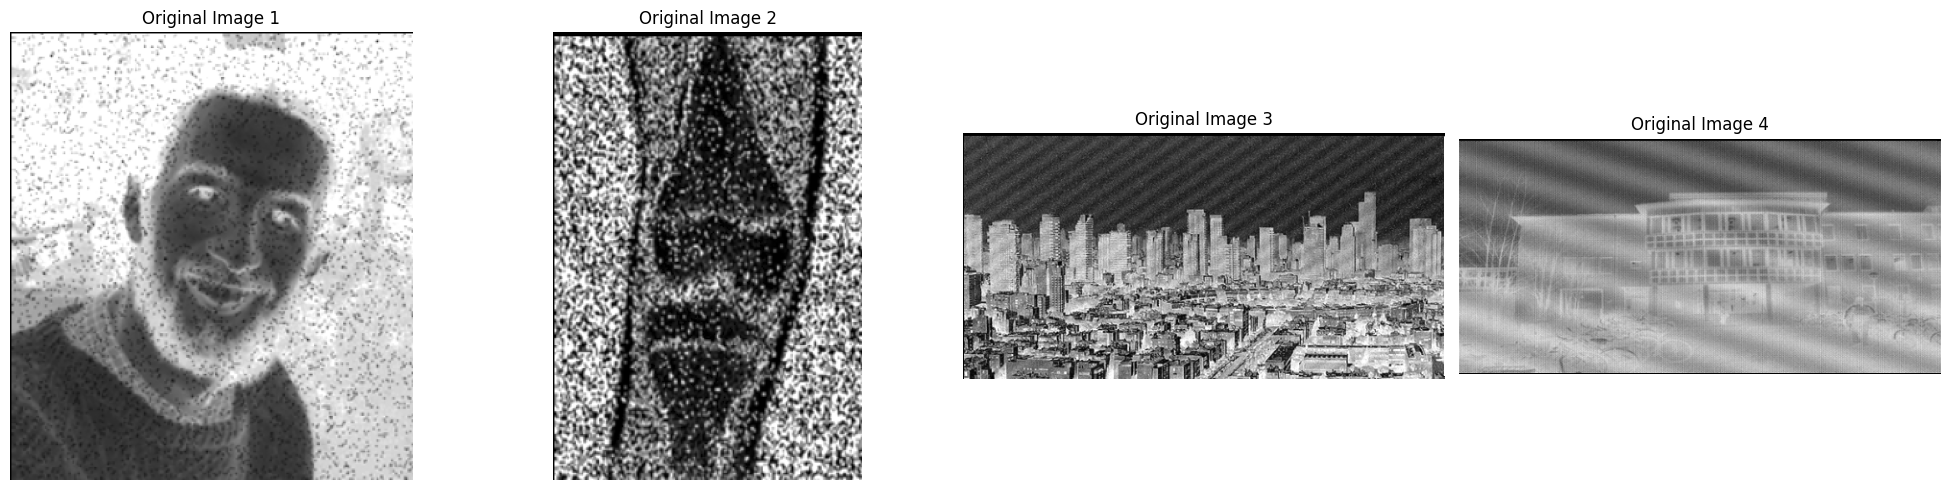

In [4]:
fig, axes = plt.subplots(1, len(images), figsize=(5 * len(images), 5))

if len(images) == 1:
    axes = [axes]

for i, img in enumerate(images):
    axes[i].imshow(img, cmap="gray", vmin=0, vmax=255)
    axes[i].set_title("Original Image " + str(i + 1))
    axes[i].axis("off")

plt.tight_layout()
plt.savefig(os.path.join(output_dir, "01_Original_Images.png"), dpi=200, bbox_inches="tight")
plt.show()

## 4. Define non-linear filters

- **Median filter:** Replaces each pixel with the median of its neighbourhood. Useful for salt-and-pepper/impulse noise.
- **Alpha-trimmed mean:** Sorts neighbourhood values, removes a selected number of lowest and highest values, then averages the remaining values. Useful for some mixed-noise cases.
- **Bilateral filter:** Smooths while considering both spatial distance and intensity difference. It can preserve edges, but may leave isolated impulse noise.
- **Minimum and maximum rank filters:** Minimum filtering suppresses bright impulses; maximum filtering suppresses dark impulses. They can distort object size and boundaries, so they are included for comparison, not assumed to be best.

In [5]:
def alpha_trimmed_mean(img, k=3, d=2):
    """
    Alpha-trimmed mean filter.
    k: odd window size
    d: total number of sorted values removed (lowest + highest)
    """
    if k % 2 == 0:
        raise ValueError("Window size k must be odd.")
    if d < 0 or d >= k * k:
        raise ValueError("d must be between 0 and k*k - 1.")

    pad = k // 2
    padded = np.pad(img, pad, mode="reflect")
    windows = np.lib.stride_tricks.sliding_window_view(padded, (k, k))
    values = np.sort(windows.reshape(img.shape[0], img.shape[1], k * k), axis=2)

    low = d // 2
    high = d - low

    if high == 0:
        kept = values[:, :, low:]
    else:
        kept = values[:, :, low:-high]

    return np.mean(kept, axis=2).astype(np.uint8)


def apply_filters(img):
    results = {
        "Original": img,
        "Median 3x3": cv2.medianBlur(img, 3),
        "Median 5x5": cv2.medianBlur(img, 5),
        "Median 7x7": cv2.medianBlur(img, 7),
        "Alpha-trimmed 3x3 (d=2)": alpha_trimmed_mean(img, 3, 2),
        "Bilateral": cv2.bilateralFilter(img, d=7, sigmaColor=50, sigmaSpace=50),
        "Minimum 3x3": cv2.erode(img, np.ones((3, 3), np.uint8)),
        "Maximum 3x3": cv2.dilate(img, np.ones((3, 3), np.uint8))
    }
    return results

## 5. Apply filters and display comparisons

Each row corresponds to one input image. The notebook saves one comparison screenshot per image and one combined screenshot.

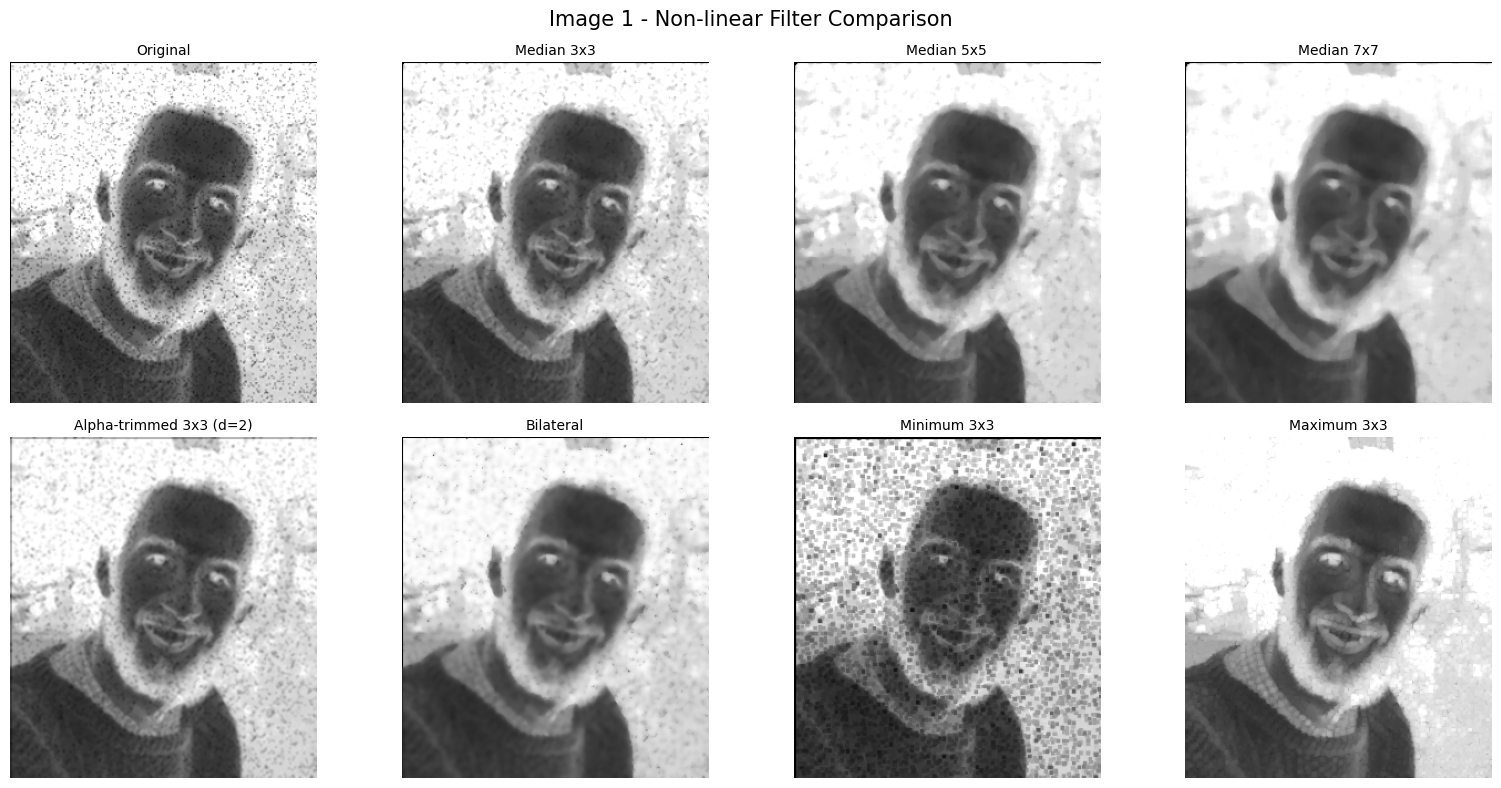

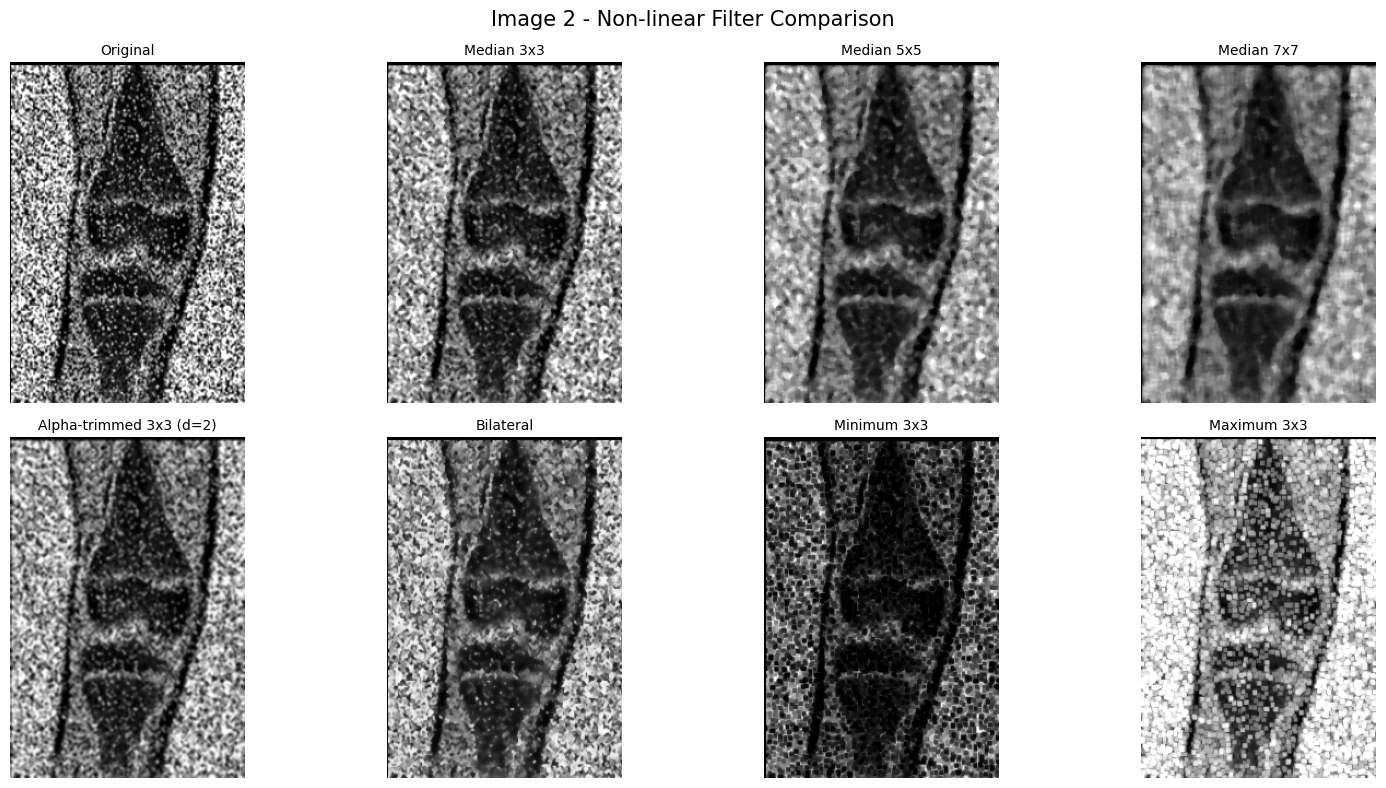

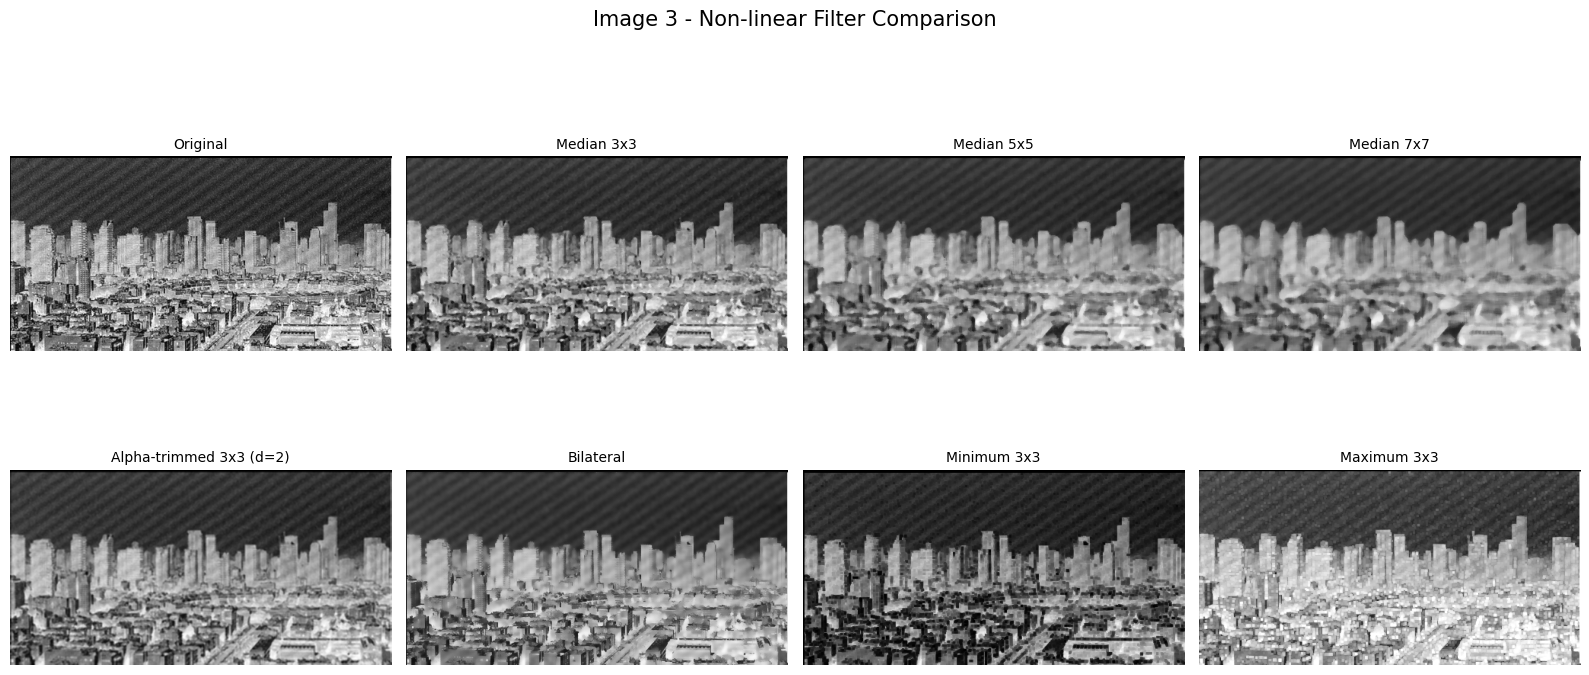

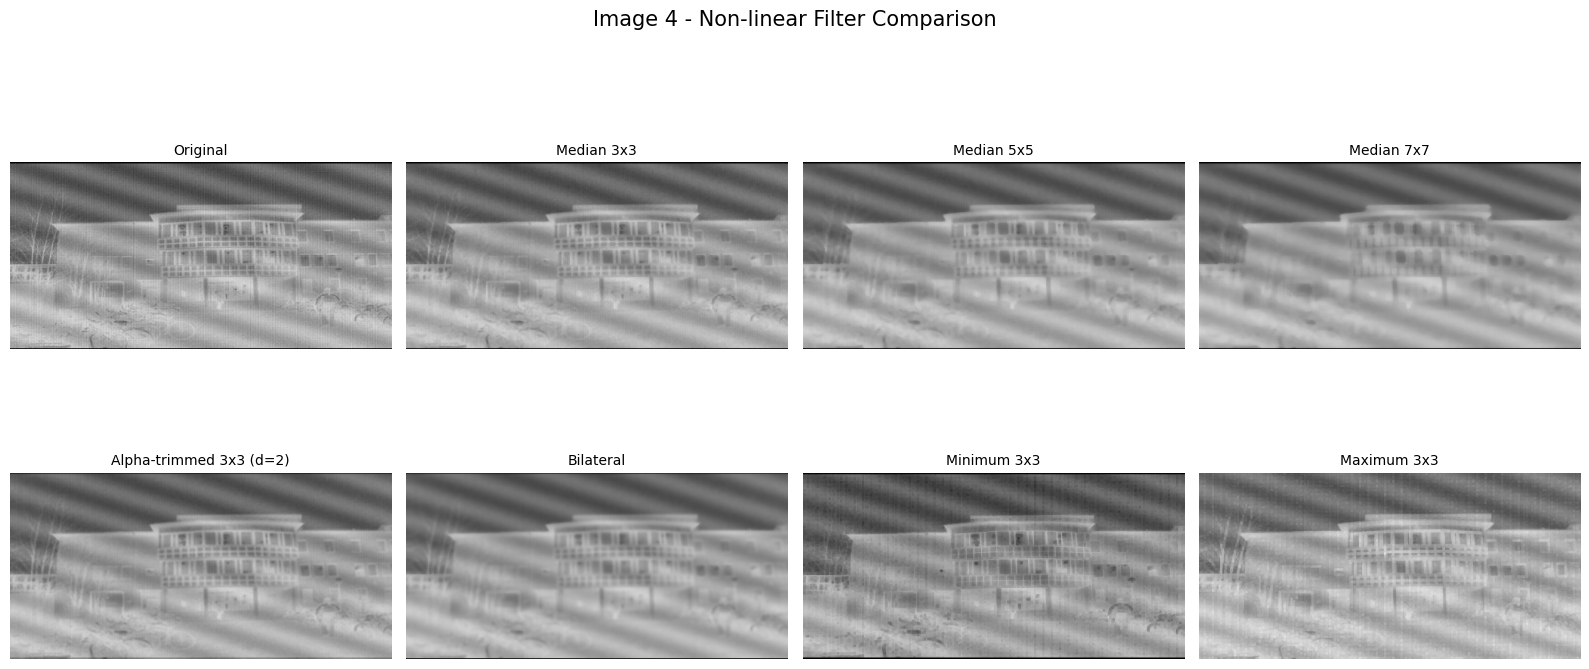

Filter comparisons and individual filtered images saved in: d:\MARWADI\YEAR3\SEM5\DSIP\OPE\OPE5\OPE7_Results


In [6]:
all_results = []

for image_number, img in enumerate(images, start=1):
    results = apply_filters(img)
    all_results.append(results)

    names = list(results.keys())
    fig, axes = plt.subplots(2, 4, figsize=(16, 8))
    axes = axes.ravel()

    for j, name in enumerate(names):
        axes[j].imshow(results[name], cmap="gray", vmin=0, vmax=255)
        axes[j].set_title(name, fontsize=10)
        axes[j].axis("off")

    fig.suptitle("Image " + str(image_number) + " - Non-linear Filter Comparison", fontsize=15)
    plt.tight_layout()
    save_path = os.path.join(output_dir, f"02_Image_{image_number}_Filter_Comparison.png")
    plt.savefig(save_path, dpi=200, bbox_inches="tight")
    plt.show()
    plt.close()

    # Save each filtered image separately
    for name, result in results.items():
        safe_name = name.replace(" ", "_").replace("(", "").replace(")", "").replace("=", "")
        cv2.imwrite(
            os.path.join(output_dir, f"Image_{image_number}_{safe_name}.png"),
            result
        )

print("Filter comparisons and individual filtered images saved in:", os.path.abspath(output_dir))

## 6. Compare edge strength

Sobel gradients are used to estimate average edge strength. A lower value after filtering can mean noise has been reduced, but it can also mean real edges and fine details have been removed.

Therefore:
- Do not interpret the highest edge strength as automatically best.
- Compare this table with the actual displayed images.
- There is no clean reference image, so this is not a true edge-preservation accuracy score.

In [ ]:
def edge_strength(img):
    gx = cv2.Sobel(img, cv2.CV_64F, 1, 0, ksize=3)
    gy = cv2.Sobel(img, cv2.CV_64F, 0, 1, ksize=3)
    magnitude = np.sqrt(gx ** 2 + gy ** 2)
    return float(np.mean(magnitude))


metric_rows = []

for image_number, results in enumerate(all_results, start=1):
    original_strength = edge_strength(results["Original"])

    for filter_name, filtered_img in results.items():
        strength = edge_strength(filtered_img)

        if original_strength != 0:
            retention = (strength / original_strength) * 100
        else:
            retention = 0

        metric_rows.append({
            "Image": image_number,
            "Filter": filter_name,
            "Mean Edge Strength": round(strength, 2),
            "Edge Strength (% of Original)": round(retention, 2)
        })

edge_table = pd.DataFrame(metric_rows)
display(edge_table)

edge_table.to_csv(os.path.join(output_dir, "Edge_Strength_Comparison.csv"), index=False)
print("Edge comparison CSV saved.")

## 7. Compare median window sizes separately

This view makes it easier to observe the trade-off between noise reduction and loss of detail as the median window increases.

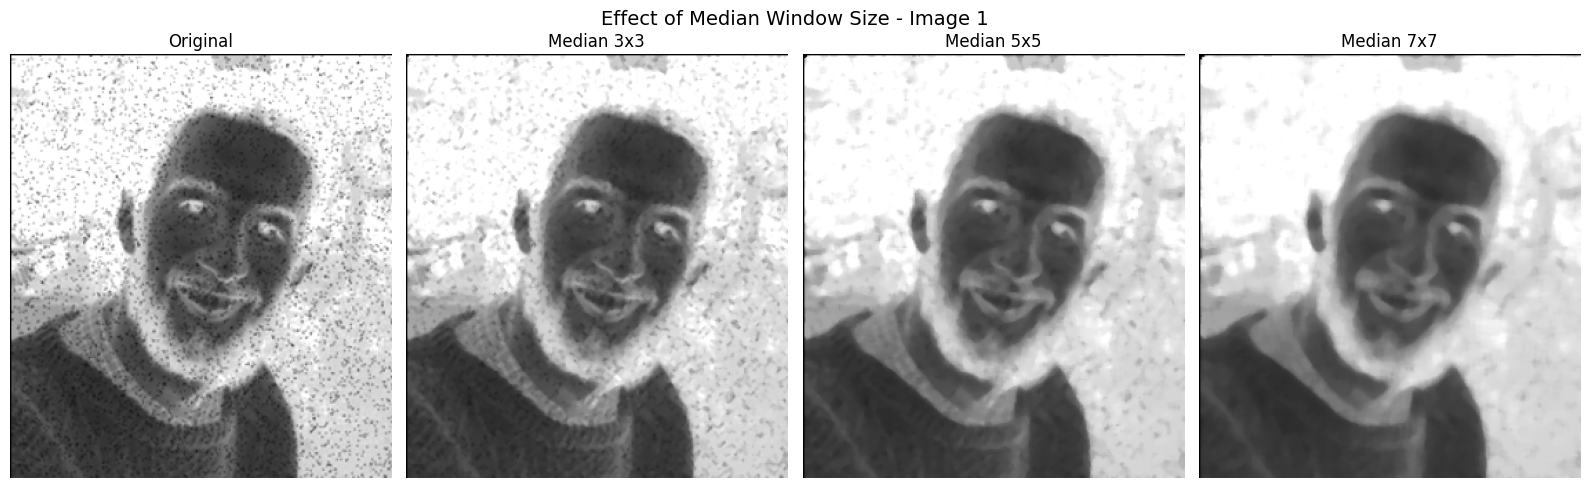

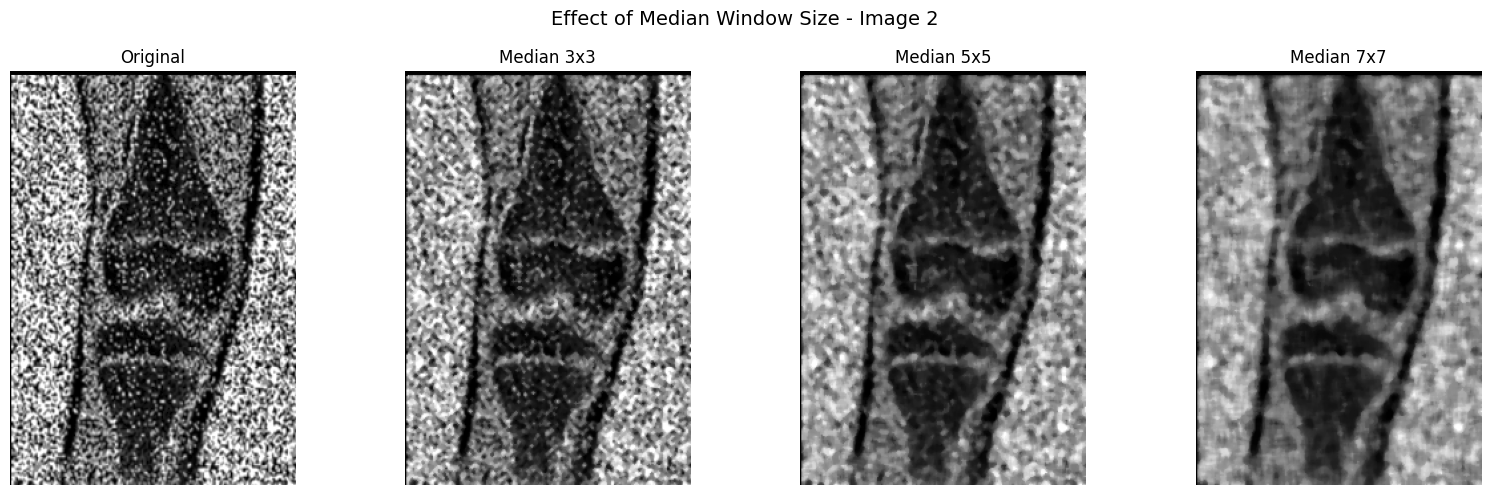

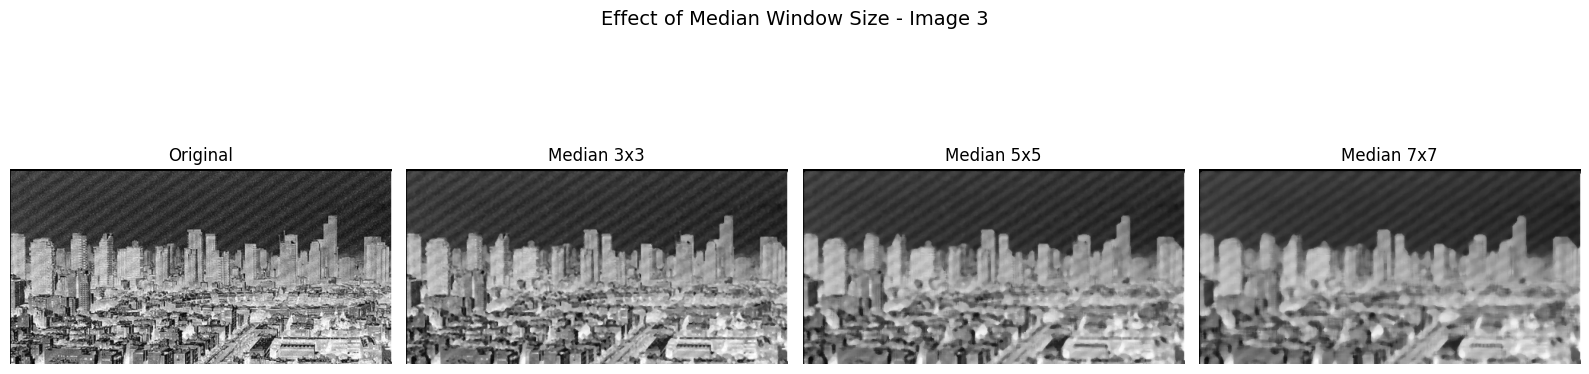

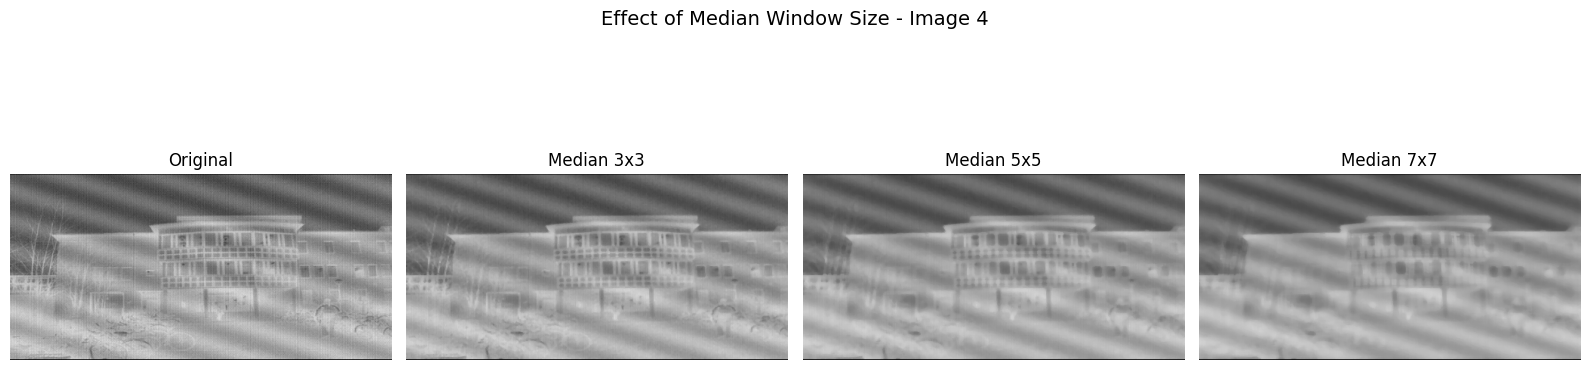

In [8]:
for image_number, results in enumerate(all_results, start=1):
    names = ["Original", "Median 3x3", "Median 5x5", "Median 7x7"]

    fig, axes = plt.subplots(1, 4, figsize=(16, 5))

    for ax, name in zip(axes, names):
        ax.imshow(results[name], cmap="gray", vmin=0, vmax=255)
        ax.set_title(name)
        ax.axis("off")

    fig.suptitle(f"Effect of Median Window Size - Image {image_number}", fontsize=14)
    plt.tight_layout()
    plt.savefig(
        os.path.join(output_dir, f"03_Image_{image_number}_Median_Size_Comparison.png"),
        dpi=200,
        bbox_inches="tight"
    )
    plt.show()
    plt.close()